# Crop Yield Prediction using Machine Learning

## 1. Introduction
**Objective:** Predict crop yield (hg/ha) from country, crop type, year, rainfall, pesticide use and temperature, and find out which factors influence yield the most.

**Dataset:** FAO / World Bank crop yield data (`yield_df.csv`).

| Column | Description |
|---|---|
| Area | Country |
| Item | Crop type |
| Year | Year of record |
| hg/ha_yield | Crop yield in hectograms per hectare (**target**) |
| average_rain_fall_mm_per_year | Average yearly rainfall (mm) |
| pesticides_tonnes | Pesticide use (tonnes) |
| avg_temp | Average temperature (deg C) |

**Workflow:** Data loading -> Cleaning -> EDA -> Preprocessing -> Model comparison -> Tuning -> Evaluation -> Feature importance -> Conclusion.

## 2. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings


sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## 3. Load and Inspect Data

In [2]:
df = pd.read_csv("data/yield_df.csv")
df.head()

,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


In [3]:
# Remove the useless index column
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

print("Shape:", df.shape)
print()
df.info()

Shape: (28242, 7)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28242 entries, 0 to 28241
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Area                           28242 non-null  object 
 1   Item                           28242 non-null  object 
 2   Year                           28242 non-null  int64  
 3   hg/ha_yield                    28242 non-null  int64  
 4   average_rain_fall_mm_per_year  28242 non-null  float64
 5   pesticides_tonnes              28242 non-null  float64
 6   avg_temp                       28242 non-null  float64
dtypes: float64(3), int64(2), object(2)
memory usage: 1.5+ MB


## 4. Data Cleaning
Checks: missing values, duplicates, and non-numeric entries in the rainfall column.

In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
Area                             0
Item                             0
Year                             0
hg/ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64

Duplicate rows: 2310


In [5]:
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates after removal:", df.duplicated().sum())
print("Shape after removing duplicates:", df.shape)

Duplicates after removal: 0
Shape after removing duplicates: (25932, 7)


In [6]:
# The rainfall column can contain text values , so we convert to numeric
# and drop rows that cannot be converted.
before = len(df)
df["average_rain_fall_mm_per_year"] = pd.to_numeric(df["average_rain_fall_mm_per_year"], errors="coerce")
df = df.dropna(subset=["average_rain_fall_mm_per_year"]).reset_index(drop=True)
print(f"Rows dropped due to non-numeric rainfall: {before - len(df)}")
print("Final shape:", df.shape)

Rows dropped due to non-numeric rainfall: 0
Final shape: (25932, 7)


**Observation:** After cleaning, the data has no duplicates, no missing values and all numeric columns have a numeric type, so it is ready for analysis.

## 5. Exploratory Data Analysis (EDA)

### 5.1 Summary Statistics

In [7]:
target = "hg/ha_yield"
num_cols = ["Year", "average_rain_fall_mm_per_year", "pesticides_tonnes", "avg_temp"]

display(df.describe().T)
print("Number of countries:", df["Area"].nunique())
print("Number of crops    :", df["Item"].nunique())
print("Year range         :", df["Year"].min(), "-", df["Year"].max())

,count,mean,std,min,25%,50%,75%,max
Year,25932.0,2001.556455,7.055924,1990.00,1995.00,2001.00,2008.00,2013.00
hg/ha_yield,25932.0,76978.132925,84647.605552,50.00,19996.00,39530.00,104168.00,501412.00
average_rain_fall_mm_per_year,25932.0,1146.836688,717.391098,51.00,593.00,1083.00,1668.00,3240.00
pesticides_tonnes,25932.0,34782.573241,57228.568244,0.04,1597.00,15373.00,45620.00,367778.00
avg_temp,25932.0,20.422251,6.439402,1.30,16.58,21.42,26.06,30.65


Number of countries: 101
Number of crops    : 10
Year range         : 1990 - 2013


**Observation:** Note the very different scales of the columns (for example, pesticides in thousands of tonnes versus temperature in tens of degrees). This is why feature scaling is needed for linear models.

### 5.2 Target Variable: Yield Distribution

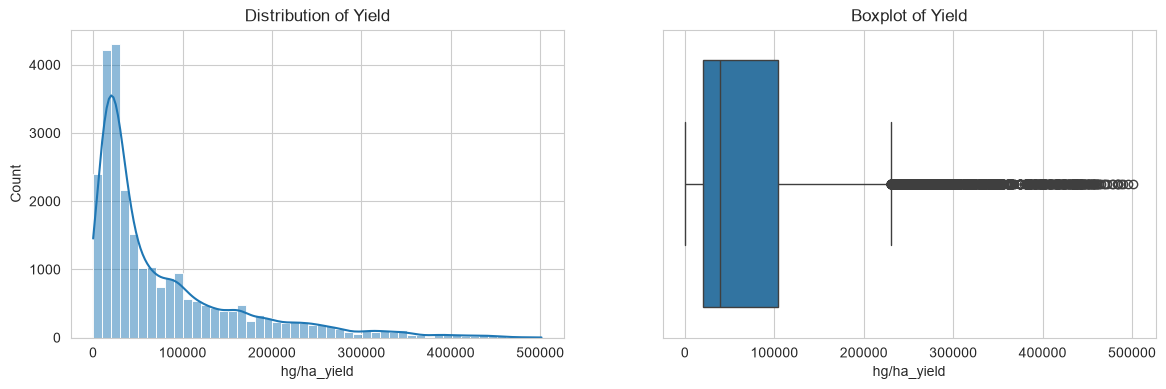

Skewness: 1.81


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df[target], bins=50, kde=True, ax=ax[0])
ax[0].set_title("Distribution of Yield")
sns.boxplot(x=df[target], ax=ax[1])
ax[1].set_title("Boxplot of Yield")
plt.show()

print("Skewness:", round(df[target].skew(), 2))

**Observation:** Yield is right-skewed with a long tail of high values. These are mostly genuine (crops like potatoes and cassava naturally have much higher yields), so they are kept in the data.

### 5.3 Univariate Analysis

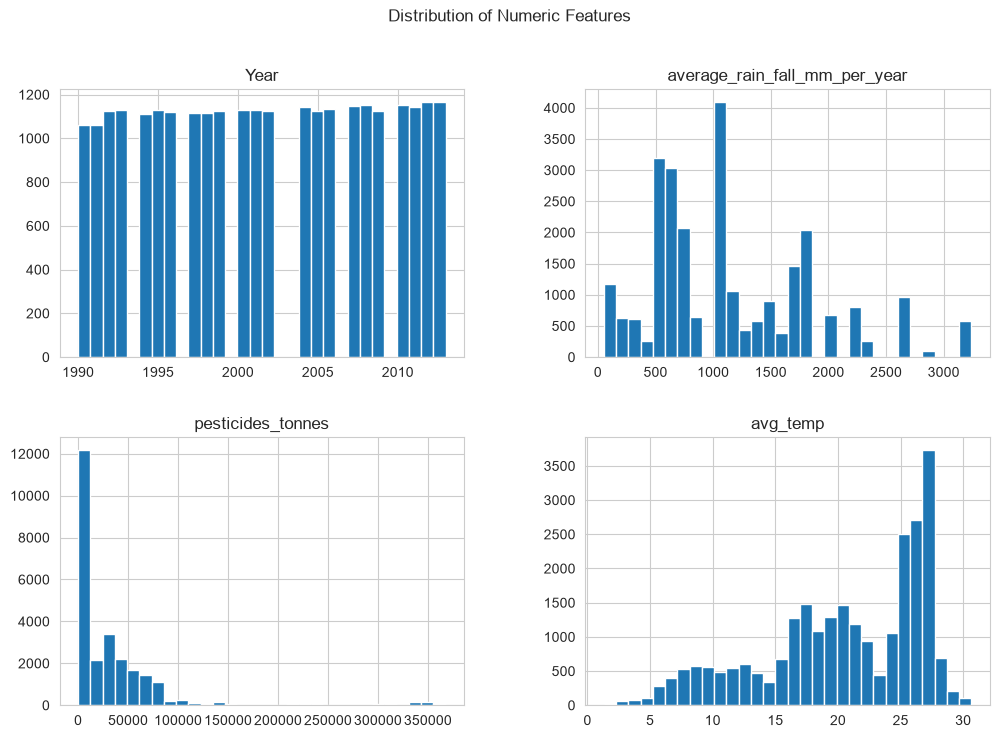

In [9]:
df[num_cols].hist(bins=30, figsize=(12, 8))
plt.suptitle("Distribution of Numeric Features")
plt.show()

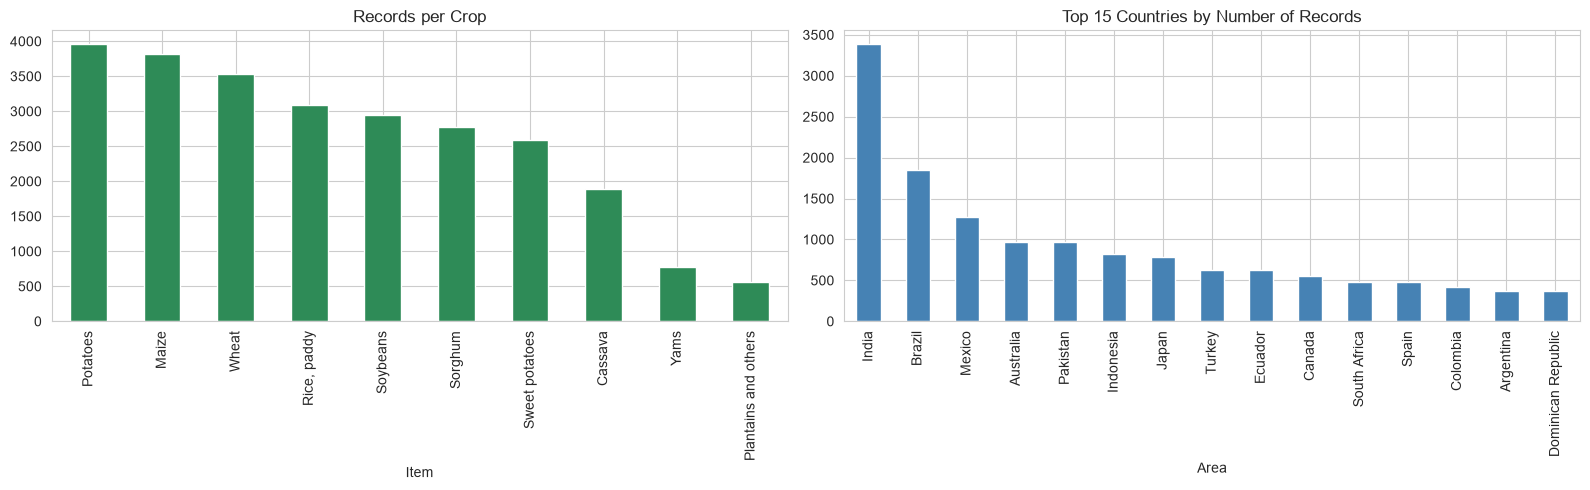

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
df["Item"].value_counts().plot(kind="bar", ax=ax[0], color="seagreen")
ax[0].set_title("Records per Crop")
df["Area"].value_counts().head(15).plot(kind="bar", ax=ax[1], color="steelblue")
ax[1].set_title("Top 15 Countries by Number of Records")
plt.tight_layout()
plt.show()

### 5.4 Yield by Crop
Average (mean) yield is used instead of the total, because the total is biased towards crops or countries with more records.

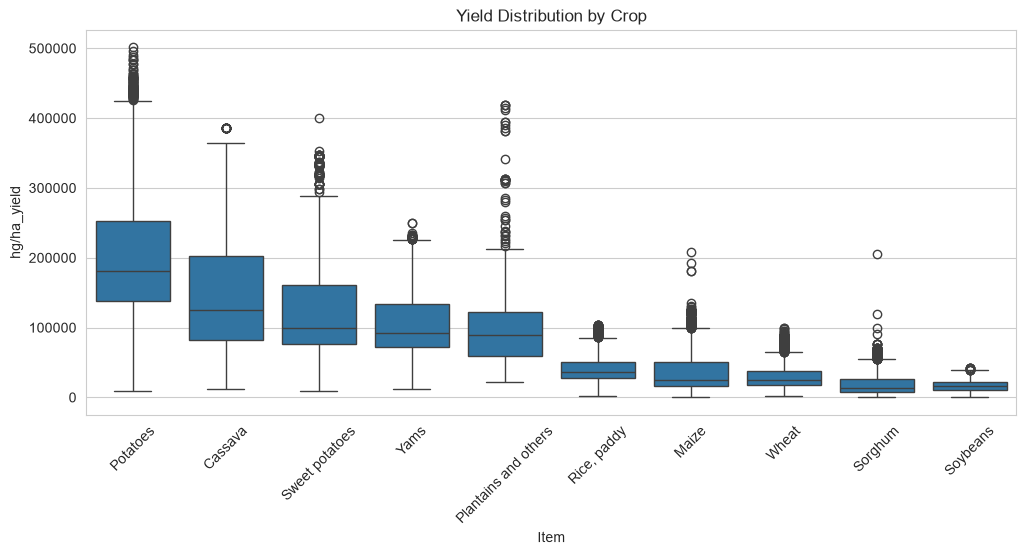

Item
Potatoes                198666.0
Cassava                 145650.0
Sweet potatoes          119657.0
Yams                    112106.0
Plantains and others    106041.0
Rice, paddy              41296.0
Maize                    37139.0
Wheat                    30126.0
Sorghum                  19100.0
Soybeans                 16992.0
Name: hg/ha_yield, dtype: float64

In [11]:
order = df.groupby("Item")[target].mean().sort_values(ascending=False).index
plt.figure(figsize=(12, 5))
sns.boxplot(x="Item", y=target, data=df, order=order)
plt.xticks(rotation=45)
plt.title("Yield Distribution by Crop")
plt.show()

df.groupby("Item")[target].mean().sort_values(ascending=False).round(0)

**Observation:** Crop type has a very strong effect on yield. Root crops (potatoes, cassava, sweet potatoes) are far above cereals and pulses, so `Item` should be a key predictor.

### 5.5 Yield by Country

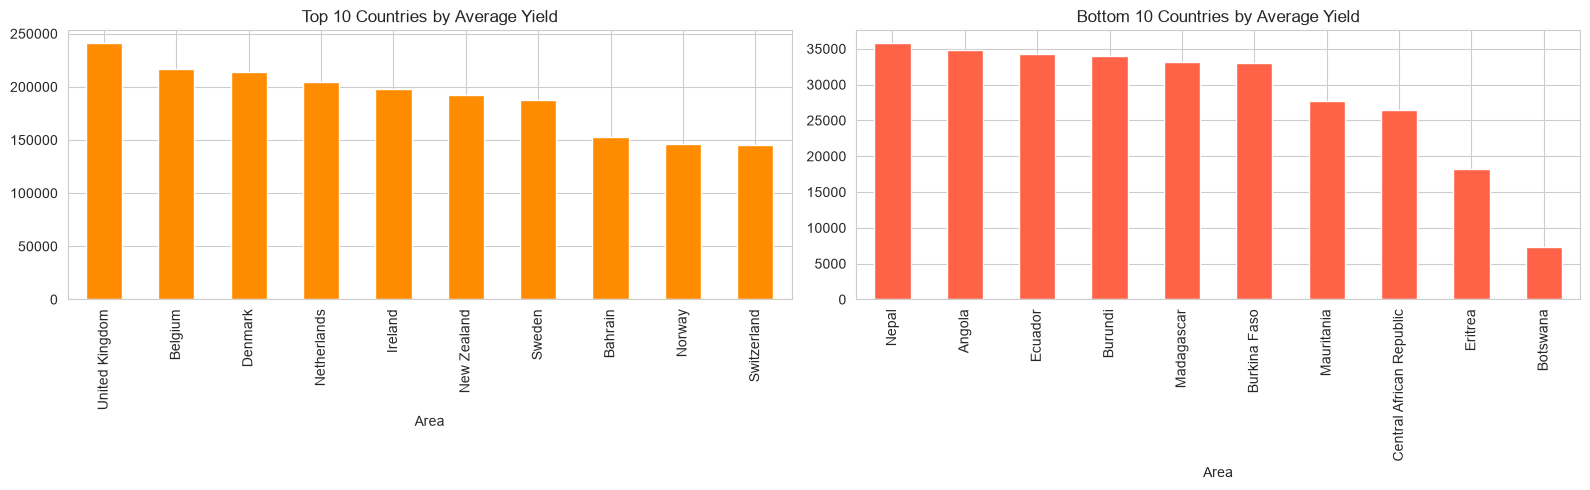

In [12]:
country_mean = df.groupby("Area")[target].mean().sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
country_mean.head(10).plot(kind="bar", ax=ax[0], color="darkorange")
ax[0].set_title("Top 10 Countries by Average Yield")
country_mean.tail(10).plot(kind="bar", ax=ax[1], color="tomato")
ax[1].set_title("Bottom 10 Countries by Average Yield")
plt.tight_layout()
plt.show()

### 5.6 Yield Trend over Time

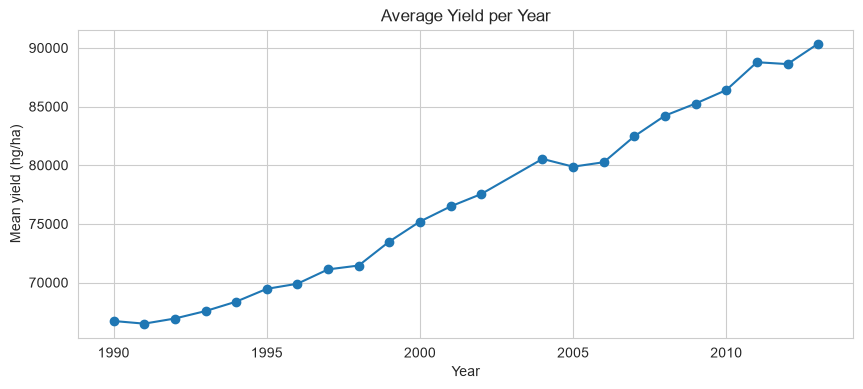

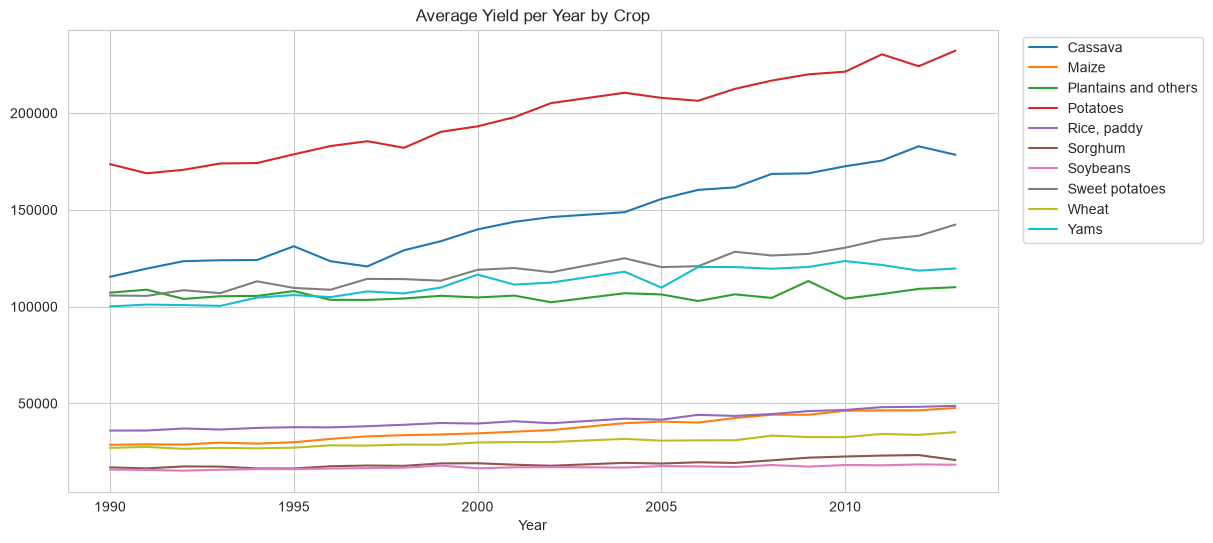

In [13]:
plt.figure(figsize=(10, 4))
df.groupby("Year")[target].mean().plot(marker="o")
plt.title("Average Yield per Year")
plt.ylabel("Mean yield (hg/ha)")
plt.show()

plt.figure(figsize=(12, 6))
df.pivot_table(values=target, index="Year", columns="Item", aggfunc="mean").plot(ax=plt.gca())
plt.title("Average Yield per Year by Crop")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Observation:** Yields show a slight upward trend over the years, which is consistent with improvements in farming technology.

### 5.7 Relationship of Numeric Features with Yield

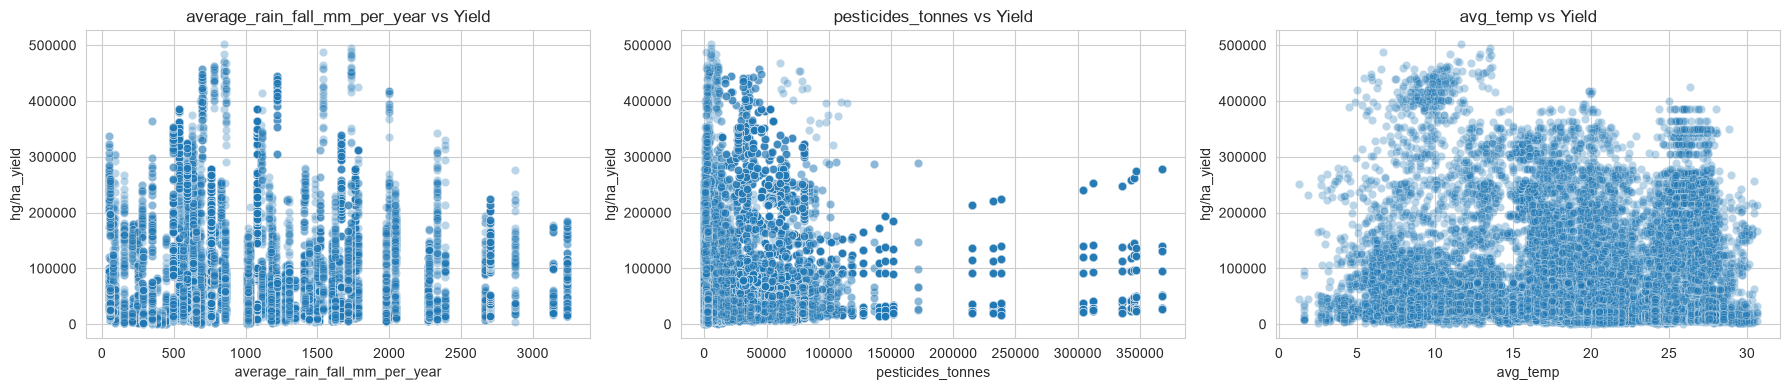

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, col in zip(ax, ["average_rain_fall_mm_per_year", "pesticides_tonnes", "avg_temp"]):
    sns.scatterplot(x=df[col], y=df[target], alpha=0.3, ax=a)
    a.set_title(f"{col} vs Yield")
plt.tight_layout()
plt.show()

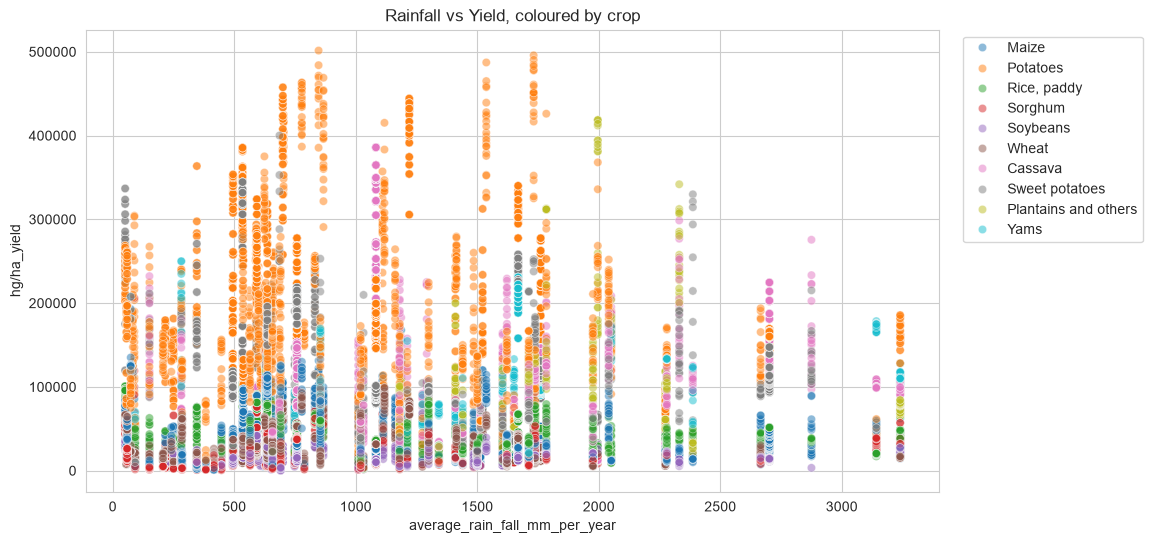

In [15]:
plt.figure(figsize=(11, 6))
sns.scatterplot(x="average_rain_fall_mm_per_year", y=target, hue="Item", data=df, alpha=0.5)
plt.title("Rainfall vs Yield, coloured by crop")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Observation:** No single numeric feature shows a clean linear relationship with yield. The pattern depends heavily on the crop type, which suggests that non-linear models should perform better than linear ones.

### 5.8 Correlation Analysis

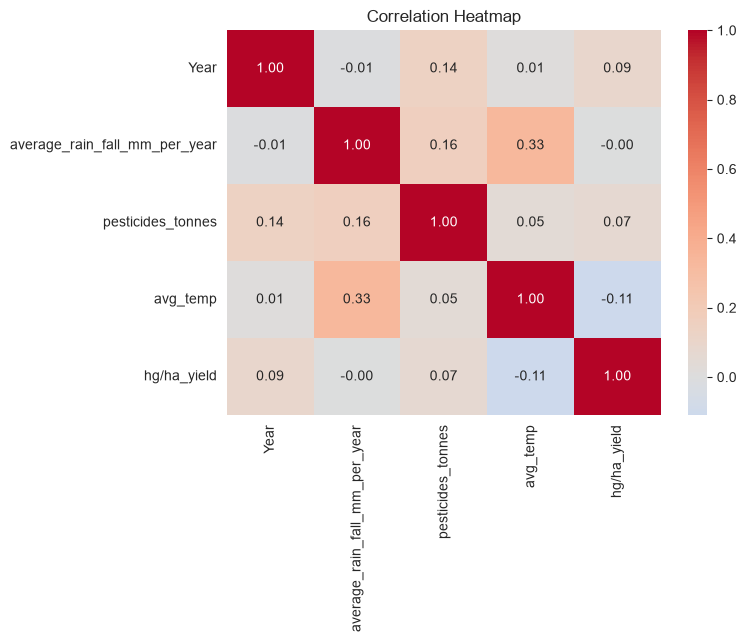

In [16]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols + [target]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

**Observation:** Correlations between the numeric features and yield are weak. The most informative features are the categorical ones (`Item`, `Area`), which is why they have to be encoded properly.

### 5.9 Outlier Check (IQR method)

In [17]:
Q1, Q3 = df[target].quantile([0.25, 0.75])
IQR = Q3 - Q1
low, high = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers = df[(df[target] < low) | (df[target] > high)]
print(f"Outliers in yield: {len(outliers)} ({len(outliers)/len(df)*100:.1f}% of data)")
print("Crops with outliers:")
print(outliers["Item"].value_counts())

Outliers in yield: 1918 (7.4% of data)
Crops with outliers:
Item
Potatoes                1237
Cassava                  379
Sweet potatoes           253
Plantains and others      38
Yams                      11
Name: count, dtype: int64


**Decision:** The outliers come mostly from high-yield crops such as potatoes and cassava, so they are valid values and are **kept**. Tree-based models are also robust to outliers.

## 6. Preprocessing and Train/Test Split
- Numeric features: standard scaling
- Categorical features (`Area`, `Item`): one-hot encoding
- 80/20 train/test split. The preprocessor is fitted **only on the training set** to avoid data leakage.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

cat_cols = ["Area", "Item"]
features = num_cols + cat_cols

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)
print("Features after encoding:", X_train_p.shape[1])

Train: (20745, 6)  Test: (5187, 6)
Features after encoding: 115


## 7. Model Building and Comparison
Models compared: Linear Regression, Ridge, Lasso, KNN, Decision Tree, Random Forest, Gradient Boosting (and XGBoost if installed).
Metrics: **R2**, **MAE**, **RMSE**, with a 5-fold cross-validation R2 and train R2 to check for overfitting.

In [19]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [29]:

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=10000),
    "KNN": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

try:
    from xgboost import XGBRegressor
    models["XGBoost"] = XGBRegressor(random_state=42, n_jobs=-1)
except ImportError:
    print("xgboost not installed, skipping (pip install xgboost to include it)")

results = []
for name, model in models.items():
    model.fit(X_train_p, y_train)
    pred = model.predict(X_test_p)
    cv = cross_val_score(model, X_train_p, y_train, cv=5, scoring="r2", n_jobs=-1).mean()
    results.append({
        "Model": name,
        "Train R2": r2_score(y_train, model.predict(X_train_p)),
        "Test R2": r2_score(y_test, pred),
        "CV R2 (5-fold)": cv,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
    })

results_df = pd.DataFrame(results).sort_values("Test R2", ascending=False).reset_index(drop=True)
results_df.round(3)

,Model,Train R2,Test R2,CV R2 (5-fold),MAE,RMSE
0,Random Forest,0.998,0.984,0.986,4036.531,10678.657
1,KNN,0.991,0.984,0.982,4719.050,10888.293
2,Decision Tree,1.000,0.977,0.977,4243.646,13037.181
3,XGBoost,0.981,0.968,0.972,8655.137,15150.239
4,Gradient Boosting,0.875,0.862,0.868,20294.773,31670.116
5,Linear Regression,0.751,0.749,0.748,29920.730,42681.455
6,Lasso,0.751,0.749,0.748,29905.908,42686.392
7,Ridge,0.751,0.749,0.748,29885.447,42691.863


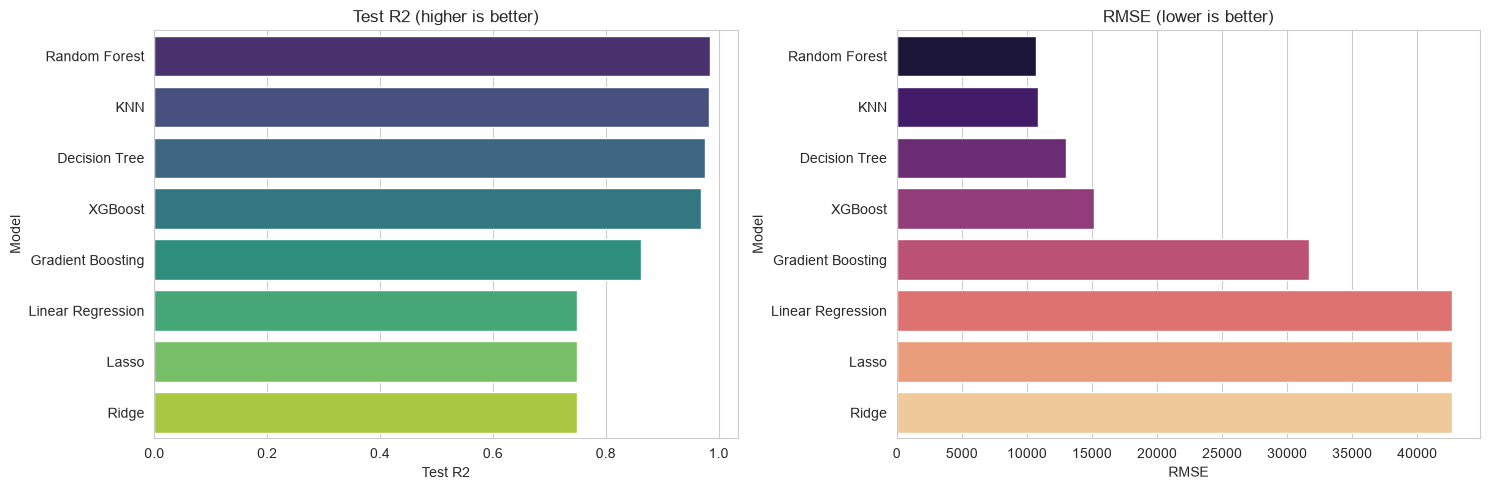

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x="Test R2", y="Model",hue="Model",legend=False, data=results_df, ax=ax[0], palette="viridis")
ax[0].set_title("Test R2 (higher is better)")
sns.barplot(x="RMSE", y="Model",hue="Model",legend=False, data=results_df, ax=ax[1], palette="magma")
ax[1].set_title("RMSE (lower is better)")
plt.tight_layout()
plt.show()

**Observation:** Linear models perform poorly because the relationship between features and yield is non-linear. Tree-based ensemble models (Random Forest, Gradient Boosting, XGBoost) perform best. A gap between Train R2 and Test R2 indicates overfitting (typical for a single Decision Tree).

## 8. Hyperparameter Tuning
The best performing ensemble model (Random Forest) is tuned with `RandomizedSearchCV`.

In [22]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.5, 1.0],
}

search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=15, cv=3, scoring="r2", random_state=42, n_jobs=-1, verbose=1,
)
search.fit(X_train_p, y_train)

print("Best parameters:", search.best_params_)
print("Best CV R2     :", round(search.best_score_, 4))

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best parameters: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 20}
Best CV R2     : 0.9818


## 9. Final Model Evaluation

In [23]:
best_model = search.best_estimator_
pred = best_model.predict(X_test_p)

print("Tuned Random Forest on the test set")
print("R2   :", round(r2_score(y_test, pred), 4))
print("MAE  :", round(mean_absolute_error(y_test, pred), 2))
print("RMSE :", round(np.sqrt(mean_squared_error(y_test, pred)), 2))

Tuned Random Forest on the test set
R2   : 0.9819
MAE  : 4839.67
RMSE : 11459.01


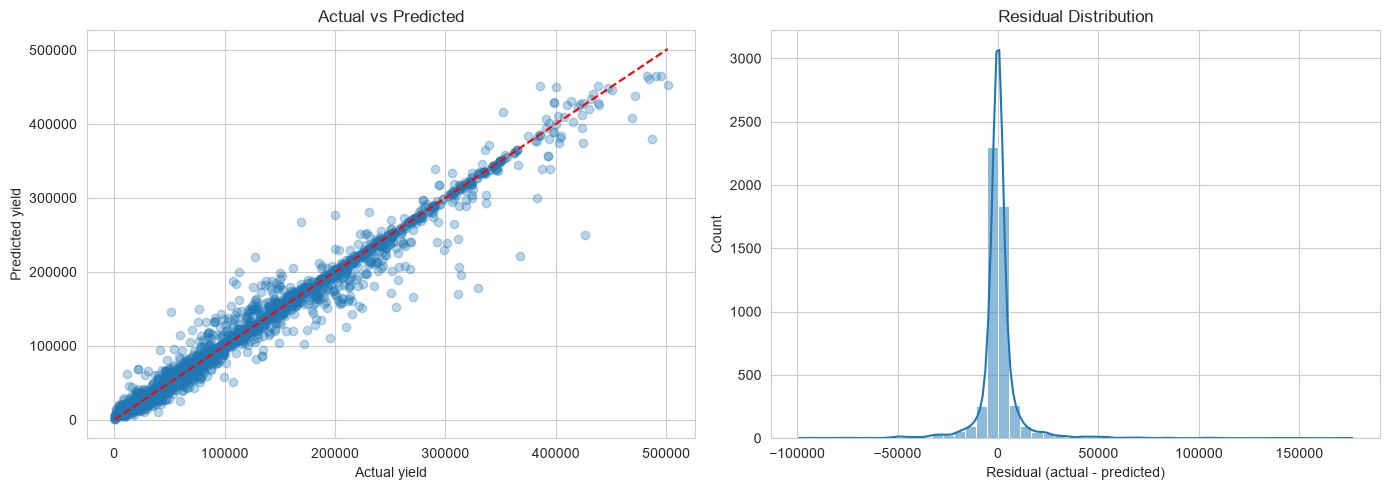

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(y_test, pred, alpha=0.3)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
ax[0].plot(lims, lims, "r--")
ax[0].set_xlabel("Actual yield")
ax[0].set_ylabel("Predicted yield")
ax[0].set_title("Actual vs Predicted")

residuals = y_test - pred
sns.histplot(residuals, bins=50, kde=True, ax=ax[1])
ax[1].set_title("Residual Distribution")
ax[1].set_xlabel("Residual (actual - predicted)")
plt.tight_layout()
plt.show()

**Observation:** Points close to the red diagonal line mean accurate predictions. Residuals centred around zero show the model is not systematically biased.

## 10. Feature Importance

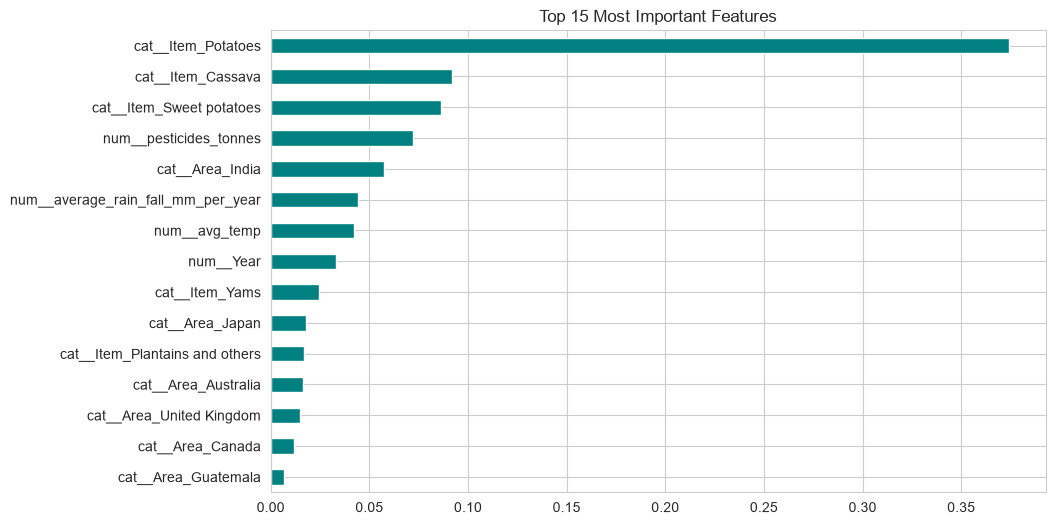

Item                             0.604
Area                             0.205
pesticides_tonnes                0.072
average_rain_fall_mm_per_year    0.044
avg_temp                         0.042
Year                             0.033
dtype: float64


In [25]:
feat_names = preprocessor.get_feature_names_out()
imp = pd.Series(best_model.feature_importances_, index=feat_names).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
imp.head(15).sort_values().plot(kind="barh", color="teal")
plt.title("Top 15 Most Important Features")
plt.show()

# Combined importance per original feature (sums the one-hot columns back together)
combined = {}
for fname, val in imp.items():
    original = fname.split("__")[1]
    for c in cat_cols:
        if original.startswith(c + "_"):
            original = c
    combined[original] = combined.get(original, 0) + val
combined = pd.Series(combined).sort_values(ascending=False)
print(combined.round(3))

## 11. Prediction System
A helper function that takes the six input values and returns the predicted yield.

In [26]:
def predict_yield(Year, rainfall, pesticides, temp, Area, Item):
    row = pd.DataFrame([{
        "Year": Year,
        "average_rain_fall_mm_per_year": rainfall,
        "pesticides_tonnes": pesticides,
        "avg_temp": temp,
        "Area": Area,
        "Item": Item,
    }])
    return best_model.predict(preprocessor.transform(row))[0]

# Example: use a real row from the dataset to sanity check
sample = df.iloc[0]
print(sample[features].to_dict())
print("Actual   :", sample[target])
print("Predicted:", round(predict_yield(sample["Year"], sample["average_rain_fall_mm_per_year"],
                                         sample["pesticides_tonnes"], sample["avg_temp"],
                                         sample["Area"], sample["Item"]), 0))

{'Year': 1990, 'average_rain_fall_mm_per_year': 1485.0, 'pesticides_tonnes': 121.0, 'avg_temp': 16.37, 'Area': 'Albania', 'Item': 'Maize'}
Actual   : 36613
Predicted: 30150.0


In [27]:
import pickle
pickle.dump(best_model, open("crop_yield_model.pkl", "wb"))
pickle.dump(preprocessor, open("preprocessor.pkl", "wb"))
print("Model and preprocessor saved.")

Model and preprocessor saved.


## 12. Conclusion

**Summary of work**
- Cleaned the FAO crop yield data (index column, duplicates, non-numeric rainfall values).
- Carried out detailed EDA covering the target distribution, crop and country comparisons, yearly trends, correlations and outliers.
- Compared multiple regression models with R2, MAE, RMSE and cross-validation.
- Tuned the best model and analysed the importance of each feature.
- Build `.pkl` model file for prediction.

**Key findings**
- Best model: **Random Forest**.
- The default **Random Forest (R² = 0.984)** performed slightly better than the **tuned version (R² = 0.982)**, so tuning gave no gain.
- Linear models performed poorly, which shows the relationship is non-linear.
- Crop type (`Item`) and country (`Area`) are the most influential features. Rainfall, temperature and pesticides contribute less.
- Yield shows a gradual upward trend over the years.

**Limitations**
- Data is aggregated at the country-year level, so local factors (soil, irrigation, seed variety) are not captured.
- Only six input features are available. Soil quality, fertilizer use and weather extremes are missing.
- The model cannot reliably predict for countries or crops it has not seen.

